# PV Plant Performance Monitoring & Forecasting

**Goal:** take raw inverter and weather data from a real solar plant, compute the KPIs an O&M team tracks, flag underperforming inverters and forecast daily generation.

**Data:** Kaggle *Solar Power Generation Data* (anikannal). Two plants in India, 34 days, 15-minute readings from ~22 inverters each plus one weather sensor per plant.

**Sections**
1. Load and clean
2. KPI calculation (yield, specific yield, Performance Ratio, availability, inverter efficiency)
3. Performance issue detection
4. Daily generation forecasting
5. Findings

In [ ]:
# import sys 
# !{sys.executable} -m pip install kagglehub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

LOCAL_DATA_PATH = "pv_data/" #solar_power_generation_data"

try:
    # kagglehub downloads and caches the dataset
    import kagglehub
    DATA_PATH = kagglehub.dataset_download("anikannal/solar-power-generation-data")
except Exception as error:
    # fallback - kagglehub is missing or cannot reach kaggle
    print("kagglehub unavailable, using local folder. Reason:", error)
    DATA_PATH = LOCAL_DATA_PATH

print("Data folder:", DATA_PATH)

## 1. Load and clean

Each plant has a generation file (one row per inverter per 15 minutes) and a weather file (one row per 15 minutes). The two plants use different date formats, so each file is parsed separately.

In [2]:
def load_plant(plant_number, date_format):
    """Load and merge the generation and weather files of one plant.

    Parameters
    ----------
    plant_number : int
        1 or 2, used to build the file names.
    date_format : str
        strftime pattern of the DATE_TIME column in the generation file.

    Returns
    -------
    pandas.DataFrame
        One row per inverter per 15-minute interval with weather columns attached.
    """
    generation = pd.read_csv(f"{DATA_PATH}/Plant_{plant_number}_Generation_Data.csv")
    weather = pd.read_csv(f"{DATA_PATH}/Plant_{plant_number}_Weather_Sensor_Data.csv")

    # Parse timestamps, the weather file always uses the ISO format
    generation["DATE_TIME"] = pd.to_datetime(generation["DATE_TIME"], format=date_format)
    weather["DATE_TIME"] = pd.to_datetime(weather["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

    # The weather file has its own SOURCE_KEY (the sensor id), drop it to avoid a clash with the inverter id
    weather = weather.drop(columns=["SOURCE_KEY", "PLANT_ID"])

    # Left join so inverter rows without a matching weather reading are kept and show up as missing
    merged = generation.merge(weather, on="DATE_TIME", how="left")
    merged["PLANT"] = f"Plant {plant_number}"
    merged["DATE"] = merged["DATE_TIME"].dt.date
    return merged


plant1 = load_plant(1, "%d-%m-%Y %H:%M")
plant2 = load_plant(2, "%Y-%m-%d %H:%M:%S")
data = pd.concat([plant1, plant2], ignore_index=True)

print(data.shape)
data.head()

(136476, 12)


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT,DATE
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,25.184316,22.857507,0.0,Plant 1,2020-05-15
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,25.184316,22.857507,0.0,Plant 1,2020-05-15
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,25.184316,22.857507,0.0,Plant 1,2020-05-15
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,25.184316,22.857507,0.0,Plant 1,2020-05-15
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,25.184316,22.857507,0.0,Plant 1,2020-05-15


In [3]:
# Basic sanity checks: duplicates, missing values and how many inverters each plant has
print("Duplicate rows:", data.duplicated(subset=["PLANT", "SOURCE_KEY", "DATE_TIME"]).sum())

print("\nMissing values per column:")
print(data.isna().sum())

print("\nInverters per plant:")
print(data.groupby("PLANT")["SOURCE_KEY"].nunique())

print("\nDate range:", data["DATE_TIME"].min(), "to", data["DATE_TIME"].max())

Duplicate rows: 0

Missing values per column:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
DC_POWER               0
AC_POWER               0
DAILY_YIELD            0
TOTAL_YIELD            0
AMBIENT_TEMPERATURE    4
MODULE_TEMPERATURE     4
IRRADIATION            4
PLANT                  0
DATE                   0
dtype: int64

Inverters per plant:
PLANT
Plant 1    22
Plant 2    22
Name: SOURCE_KEY, dtype: int64

Date range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00


In [4]:
# Unit discrepancy in the data: 
# - Plant 1 reports DC power roughly 10x higher than AC power
# - Plant 2 reports them on the same scale

# Comparing the DC/AC ratio makes this visible

ratio = data.groupby("PLANT").apply(lambda g: g["DC_POWER"].sum() / g["AC_POWER"].sum())
print("DC / AC power ratio per plant:")
print(ratio)

# Correct Plant 1 so DC power is on the same scale as AC power, an inverter cannot output more AC than it receives in DC
data.loc[data["PLANT"] == "Plant 1", "DC_POWER"] = data.loc[data["PLANT"] == "Plant 1", "DC_POWER"] / 10

DC / AC power ratio per plant:
PLANT
Plant 1    10.225465
Plant 2     1.022481
dtype: float64


In [5]:
# Drop rows with no weather reading, the KPIs below need irradiation
data = data.dropna(subset=["IRRADIATION"]).copy()

# Energy per 15-minute interval in kWh, power is in kW and an interval is a quarter of an hour
INTERVAL_HOURS = 0.25
data["AC_ENERGY_KWH"] = data["AC_POWER"] * INTERVAL_HOURS
data["DC_ENERGY_KWH"] = data["DC_POWER"] * INTERVAL_HOURS

# Irradiation in the file is an instantaneous value in kW/m2, convert to kWh/m2 per interval
data["IRRADIATION_KWH_M2"] = data["IRRADIATION"] * INTERVAL_HOURS

print(data.shape)

(136472, 15)


## 2. KPI calculation

Standard O&M KPIs, computed per plant per day:

| KPI | Definition |
|---|---|
| Energy yield | Sum of AC energy (kWh) |
| Specific yield | Energy yield / installed capacity (kWh/kWp) |
| Reference yield | Daily irradiation (kWh/m²) / 1 kW/m² STC, i.e. equivalent peak-sun hours |
| Performance Ratio (PR) | Specific yield / reference yield |
| Data availability | Share of expected 15-minute intervals that reported data |
| Inverter efficiency | AC energy / DC energy |

**Assumption:** installed capacity is not given in the dataset. Peak DC power per inverter is used as a proxy for its kWp rating, summed per plant.

In [6]:
# Capacity proxy: the highest DC power ever seen on each inverter, summed per plant

inverter_capacity = data.groupby(["PLANT", "SOURCE_KEY"])["DC_POWER"].max()
plant_capacity_kwp = inverter_capacity.groupby("PLANT").sum()

print("Estimated capacity per plant (kWp):")
print(plant_capacity_kwp.round(0))

Estimated capacity per plant (kWp):
PLANT
Plant 1    31241.0
Plant 2    30249.0
Name: DC_POWER, dtype: float64


In [7]:
def daily_plant_kpis(data, plant_capacity_kwp):
    """Compute the daily KPI table for every plant.

    Parameters
    ----------
    data : pandas.DataFrame
        Cleaned interval-level data with energy and irradiation columns.
    plant_capacity_kwp : pandas.Series
        Installed capacity per plant, indexed by plant name.

    Returns
    -------
    pandas.DataFrame
        One row per plant per day with yield, specific yield, PR, availability and efficiency.
    """
    INTERVALS_PER_DAY = 96  # 24 hours / 15 minutes
    inverters_per_plant = data.groupby("PLANT")["SOURCE_KEY"].nunique()

    daily = data.groupby(["PLANT", "DATE"]).agg(
        ac_energy_kwh=("AC_ENERGY_KWH", "sum"),
        dc_energy_kwh=("DC_ENERGY_KWH", "sum"),
        rows_reported=("SOURCE_KEY", "size"),
    ).reset_index()

    # Irradiation is the same for every inverter in a plant, so take it once per interval and sum per day
    irradiation = (
        data.drop_duplicates(subset=["PLANT", "DATE_TIME"])
        .groupby(["PLANT", "DATE"])["IRRADIATION_KWH_M2"].sum()
        .rename("irradiation_kwh_m2")
        .reset_index()
    )
    daily = daily.merge(irradiation, on=["PLANT", "DATE"])

    daily["capacity_kwp"] = daily["PLANT"].map(plant_capacity_kwp)
    daily["specific_yield"] = daily["ac_energy_kwh"] / daily["capacity_kwp"]
    daily["reference_yield"] = daily["irradiation_kwh_m2"]  # divided by 1 kW/m2 at STC
    daily["performance_ratio"] = daily["specific_yield"] / daily["reference_yield"]
    daily["availability"] = daily["rows_reported"] / (INTERVALS_PER_DAY * daily["PLANT"].map(inverters_per_plant))
    daily["inverter_efficiency"] = daily["ac_energy_kwh"] / daily["dc_energy_kwh"]
    return daily


daily_kpis = daily_plant_kpis(data, plant_capacity_kwp)
daily_kpis.round(3).head(10)

,PLANT,DATE,ac_energy_kwh,dc_energy_kwh,rows_reported,irradiation_kwh_m2,capacity_kwp,specific_yield,reference_yield,performance_ratio,availability,inverter_efficiency
0,Plant 1,2020-05-15,137707.740,140680.979,1954,4.759,31241.421,4.408,4.759,0.926,0.925,0.979
1,Plant 1,2020-05-16,142089.955,145153.438,1934,4.663,31241.421,4.548,4.663,0.975,0.916,0.979
2,Plant 1,2020-05-17,165243.847,168989.864,2112,5.733,31241.421,5.289,5.733,0.923,1.000,0.978
3,Plant 1,2020-05-18,117742.427,120313.713,2112,3.817,31241.421,3.769,3.817,0.987,1.000,0.979
4,Plant 1,2020-05-19,133062.623,135948.871,1990,4.511,31241.421,4.259,4.511,0.944,0.942,0.979
5,Plant 1,2020-05-20,131271.142,134389.644,1672,4.561,31241.421,4.202,4.561,0.921,0.792,0.977
6,Plant 1,2020-05-21,165685.612,169526.704,1368,5.889,31241.421,5.303,5.889,0.901,0.648,0.977
7,Plant 1,2020-05-22,156957.527,160517.113,2028,5.530,31241.421,5.024,5.530,0.909,0.960,0.978
8,Plant 1,2020-05-23,186471.072,190755.430,1958,6.527,31241.421,5.969,6.527,0.915,0.927,0.978
9,Plant 1,2020-05-24,174954.453,179008.847,2112,6.234,31241.421,5.600,6.234,0.898,1.000,0.977


In [8]:
# Monthly style summary: one line per plant for the whole period

summary = daily_kpis.groupby("PLANT").agg(
    total_energy_mwh=("ac_energy_kwh", lambda s: s.sum() / 1000),
    avg_specific_yield=("specific_yield", "mean"),
    avg_performance_ratio=("performance_ratio", "mean"),
    avg_availability=("availability", "mean"),
    avg_inverter_efficiency=("inverter_efficiency", "mean"),
)

summary.round(3)

,total_energy_mwh,avg_specific_yield,avg_performance_ratio,avg_availability,avg_inverter_efficiency
PLANT,,,,,
Plant 1,5291.787,4.982,0.936,0.958,0.978
Plant 2,4083.507,3.971,0.739,0.943,0.978


In [9]:
import plotly.express as px

# Interactive Performance Ratio trend per plant
fig = px.line(
    daily_kpis,
    x="DATE",
    y="performance_ratio",
    color="PLANT",
    markers=True,
    title="Daily Performance Ratio",
    labels={"DATE": "Date", "performance_ratio": "Performance Ratio", "PLANT": "Plant"},
    template="plotly_white",
    color_discrete_sequence=["#1F77B4", "#F28E2B"],
)

# Show date and PR with two decimals on hover
fig.update_traces(hovertemplate="%{x|%d %b}<br>PR: %{y:.1%}") #"%{x|%d %b}<br>PR: %{y:.2f}"


# Reference line 1: literature benchmark
# Woyte et al. (2013, Fraunhofer ISE / 3E) report typical PR of 0.7-0.9 for modern plants in moderate
# climates with well-maintained systems averaging around 0.72-0.85, so 0.75 is a conservative benchmark
# Plants in hot climates like India sit lower because of temperature losses, so this is a reference not a target
# Woyte et al., Monitoring of photovoltaic systems: good practices and systematic analysis (Fraunhofer ISE, EU PVSEC 2013)
# https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/conference-paper/28-eupvsec-2013/Woyte.pdf
LITERATURE_PR = 0.75
fig.add_hline(
    y=LITERATURE_PR,
    line_dash="dot",
    line_color="#D62728",
    annotation_text=f"Literature benchmark {LITERATURE_PR:.0%}",
    annotation_position="bottom right",
)
# fig.add_hline(y=0.75, line_dash="dash", line_color="grey", annotation_text="Target PR 75%")

# Reference line 2: period average of these plants
# Installed capacity is estimated from peak DC power, so absolute PR is indicative
# The period average is derived from the data itself and shows which days were below normal for these plants
average_pr = daily_kpis["performance_ratio"].mean()
fig.add_hline(
    y=average_pr,
    line_dash="dot",
    line_color="#2CA02C",
    annotation_text=f"Period average {average_pr:.1%}",
    annotation_position="top right",
)

# Layout: fixed y range so days are comparable, one tick per day on the x axis
fig.update_layout(
    yaxis=dict(range=[0, 1], tickformat=".0%"),
    xaxis=dict(dtick="D1", tickformat="%d %b", tickangle=-45),
    legend=dict(orientation="h", y=1.1, x=0),
    hovermode="x unified",
    height=450,
)

# scrollZoom lets the mouse wheel zoom in and out, drag to pan, double click to reset
fig.show(config={"scrollZoom": True})

## 3. Performance issue detection

Every inverter in a plant sees the same irradiation, so on any given day they should produce roughly the same energy. An inverter is flagged when its daily energy falls more than 10% below the plant median for that day.

In [10]:
UNDERPERFORMANCE_THRESHOLD = 0.10

# Daily energy per inverter
inverter_daily = data.groupby(["PLANT", "SOURCE_KEY", "DATE"])["AC_ENERGY_KWH"].sum().reset_index()

# Plant median for the same day, then the deviation of each inverter from it
plant_median = inverter_daily.groupby(["PLANT", "DATE"])["AC_ENERGY_KWH"].transform("median")
inverter_daily["deviation_from_median"] = inverter_daily["AC_ENERGY_KWH"] / plant_median - 1
inverter_daily["underperforming"] = inverter_daily["deviation_from_median"] < -UNDERPERFORMANCE_THRESHOLD


# Rank inverters by how many days they were flagged
flag_counts = (
    inverter_daily.groupby(["PLANT", "SOURCE_KEY"])
    .agg(days_flagged=("underperforming", "sum"), avg_deviation=("deviation_from_median", "mean"))
    .sort_values("days_flagged", ascending=False)
)

print("Inverters flagged on the most days:")

flag_counts.head(8).round(3)

Inverters flagged on the most days:


days_flagged  avg_deviation
PLANT   SOURCE_KEY                                  
Plant 2 Quc1TzYxW2pYoWX            30         -0.360
        Et9kgGMDl729KT4            25         -0.311
        LYwnQax7tkwH5Cb            19         -0.253
        rrq4fwE8jgrTyWY            18         -0.192
        q49J1IKaHRwDQnt            15         -0.141
        xoJJ8DcxJEcupym            13         -0.110
        81aHJ1q11NBPMrL            13         -0.142
        WcxssY2VbP4hApt            12         -0.045

In [11]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Plot the worst inverter of each plant against the plant median, one subplot per plant stacked vertically
fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=["Plant 1", "Plant 2"],
    shared_xaxes=True,
    vertical_spacing=0.12,
)

for row, plant in enumerate(["Plant 1", "Plant 2"], start=1):
    worst = flag_counts.loc[plant].index[0]
    plant_rows = inverter_daily[inverter_daily["PLANT"] == plant]
    median_series = plant_rows.groupby("DATE")["AC_ENERGY_KWH"].median()
    worst_series = plant_rows[plant_rows["SOURCE_KEY"] == worst].set_index("DATE")["AC_ENERGY_KWH"]

    # Plant median as the reference, worst inverter on top of it
    fig.add_trace(
        go.Scatter(
            x=median_series.index,
            y=median_series.values,
            mode="lines+markers",
            name=f"{plant} median",
            line=dict(color="#1F77B4"),
            hovertemplate="%{x|%d %b}<br>Median: %{y:,.0f} kWh",
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=worst_series.index,
            y=worst_series.values,
            mode="lines+markers",
            name=f"{plant} worst inverter ({worst[:6]}...)",
            line=dict(color="#D62728"),
            hovertemplate="%{x|%d %b}<br>Worst: %{y:,.0f} kWh",
        ),
        row=row,
        col=1,
    )

# Same look as the PR chart: white template, one tick per day, unified hover
# Date labels only on the bottom panel since the x axis is shared
fig.update_xaxes(dtick="D1", tickformat="%d %b", tickangle=-45, showticklabels=False, row=1, col=1)
fig.update_xaxes(dtick="D1", tickformat="%d %b", tickangle=-45, row=2, col=1)
fig.update_yaxes(title_text="Daily energy (kWh)")
fig.update_layout(
    title="Daily energy: worst inverter vs plant median",
    template="plotly_white",
    hovermode="x unified",
    legend=dict(orientation="h", y=1.08, x=0),
    height=900,
)

# Mouse wheel zooms, drag pans, double click resets
fig.show(config={"scrollZoom": True})

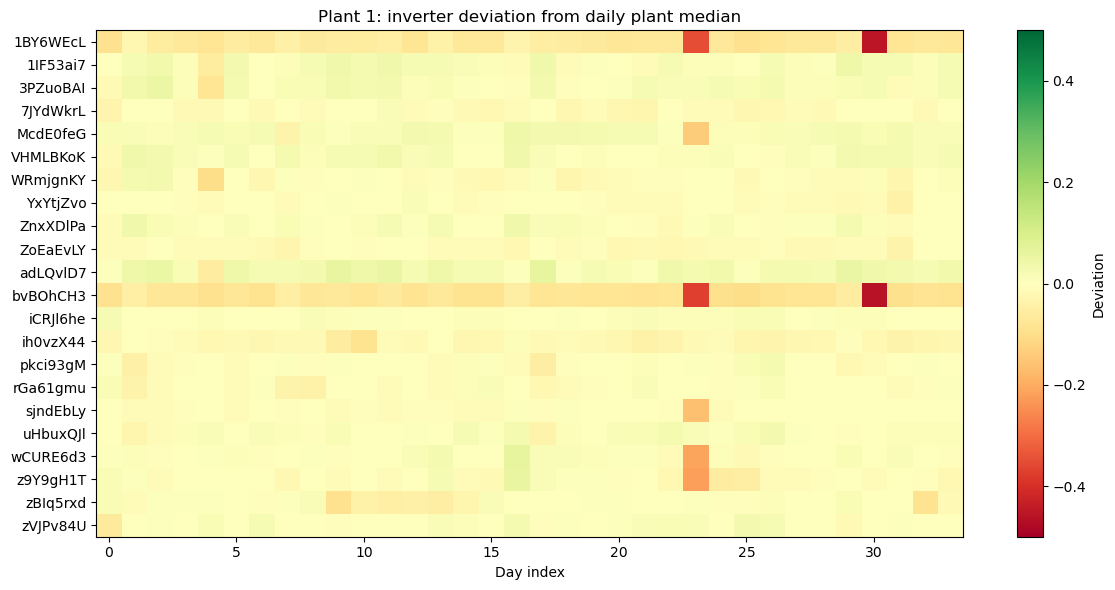

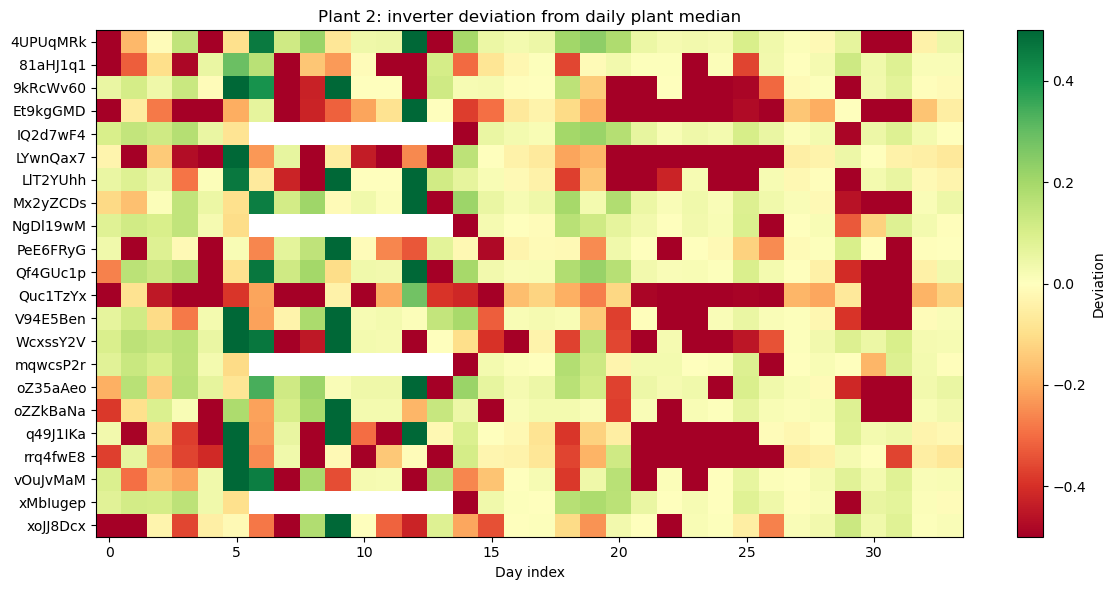

In [12]:
# Heatmap of inverter deviation from the plant median, one plant at a time
for plant in ["Plant 1", "Plant 2"]:
    pivot = inverter_daily[inverter_daily["PLANT"] == plant].pivot(
        index="SOURCE_KEY", columns="DATE", values="deviation_from_median"
    )
    fig, ax = plt.subplots(figsize=(12, 6))
    image = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=-0.5, vmax=0.5)
    ax.set_title(f"{plant}: inverter deviation from daily plant median")
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([key[:8] for key in pivot.index])
    ax.set_xlabel("Day index")
    fig.colorbar(image, ax=ax, label="Deviation")
    plt.tight_layout()
    plt.show()

### How to read the inverter heatmaps

Think of each plant as a team of 22 workers (the inverters) doing the same job under the same sun. On any given day they should all produce about the same amount of energy. The heatmap checks whether each one kept up with the rest of the team.

- **Each row** is an inverter (we see their ids).
- **Each column** is a day.
- **Each cell colour** says how that inverter performed compared with the typical inverter of the plant that day (median):
  - 🟩 **Green** - produced more than the typical inverter
  - 🟨 **Yellow** - approximately the same as the others, this is what "healthy" looks like
  - 🟥 **Red** - produced less than the others, the deeper the red the bigger the shortfall (dark red = less than half)
  - ⬜ **Grey** - no data was recorded for that inverter that day

What to look for:

- **A whole row that is orange or red** - that inverter is always behind, something is constantly wrong with it (eg dirty panels, shading, mechanical damage)
- **A red block that starts on a date and lasts several days** - a fault or outage, the start date tells us when it happened, so as to inform eg the maintenance team
- **A red column** - many inverters down on the same day
- **Grey patches** - the monitoring system might have lost contact
- **Bright green patches next to red or grey ones** - usually an illusion. When several inverters are down, the median value drops, so the normal ones look better than they really are.

A healthy plant is a nearly uniform yellow sheet. Plant 1 looks like that. Plant 2 does not.

Note: Median instead of mean was selected, because the reference needs to represent a normal inverter and the mean is streched by outliers.

## 4. Daily generation forecasting

Predict the daily AC energy of a plant from the day's irradiation and temperatures. Two models are compared against a naive "same as yesterday" baseline. The last 7 days are held out as the test set, earlier days are used for training.

In [13]:
# Daily weather features, taken once per interval then averaged or summed per day
weather_daily = (
    data.drop_duplicates(subset=["PLANT", "DATE_TIME"])
    .groupby(["PLANT", "DATE"])
    .agg(
        irradiation=("IRRADIATION_KWH_M2", "sum"),
        ambient_temp=("AMBIENT_TEMPERATURE", "mean"),
        module_temp=("MODULE_TEMPERATURE", "mean"),
    )
    .reset_index()
)

forecast_data = daily_kpis[["PLANT", "DATE", "ac_energy_kwh"]].merge(weather_daily, on=["PLANT", "DATE"])
forecast_data = forecast_data.sort_values(["PLANT", "DATE"]).reset_index(drop=True)
forecast_data.head()

,PLANT,DATE,ac_energy_kwh,irradiation,ambient_temp,module_temp
0,Plant 1,2020-05-15,137707.739851,4.759252,27.430823,32.582964
1,Plant 1,2020-05-16,142089.955357,4.662923,26.780538,31.858851
2,Plant 1,2020-05-17,165243.847321,5.732845,26.686727,32.740435
3,Plant 1,2020-05-18,117742.427232,3.816621,23.850938,27.814344
4,Plant 1,2020-05-19,133062.622768,4.511215,25.338021,29.725163



Plant 1
            model   MAE_kWh  MAPE
Naive (yesterday) 19331.055 0.124
Linear regression  3488.386 0.025
Gradient boosting  4264.016 0.030

Plant 2
            model   MAE_kWh  MAPE
Naive (yesterday) 16718.502 0.164
Linear regression  9282.533 0.097
Gradient boosting  5909.110 0.056





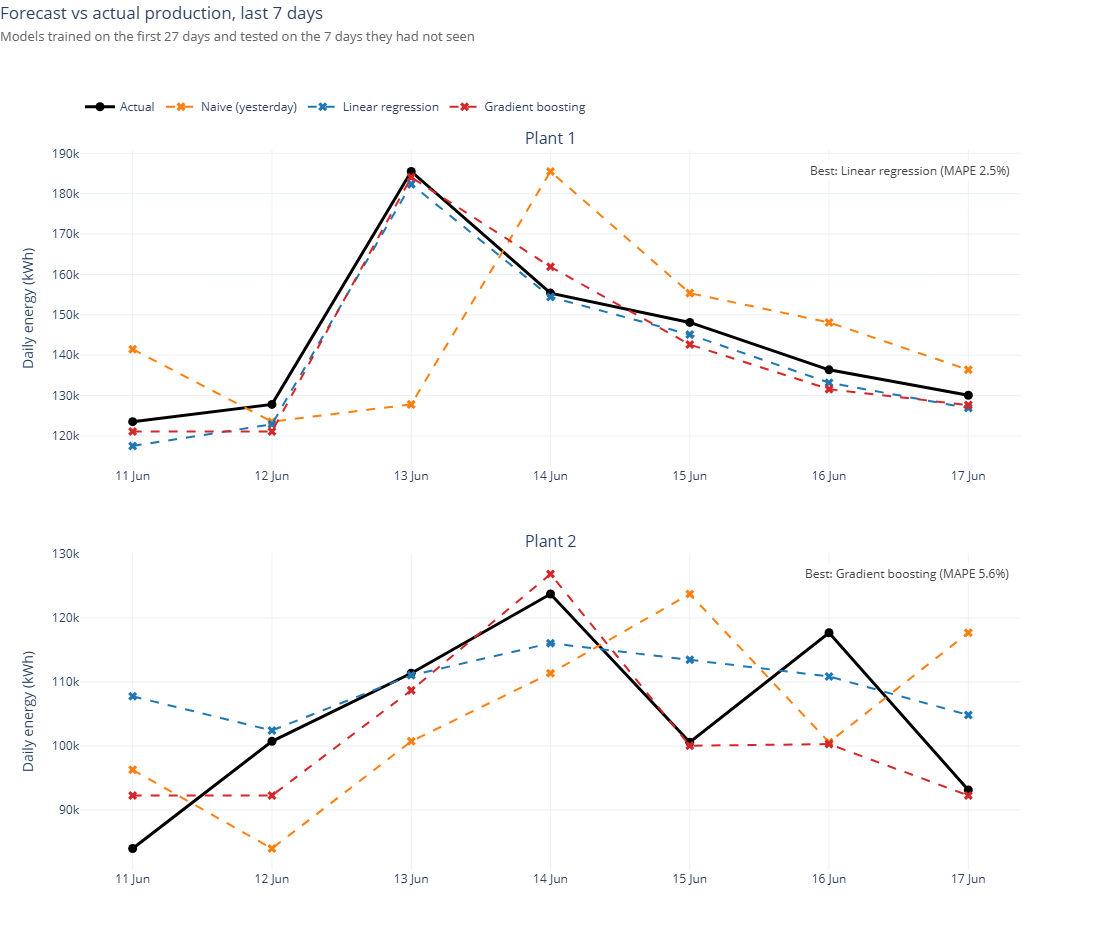

In [22]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

MODEL_COLOURS = {
    "Naive (yesterday)": "#FF7F0E",   # orange
    "Linear regression": "#1F77B4",   # blue
    "Gradient boosting": "#D62728",   # red
}

fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=["Plant 1", "Plant 2"],
    vertical_spacing=0.12,
)

for row, plant in enumerate(["Plant 1", "Plant 2"], start=1):
    plant_rows = forecast_data[forecast_data["PLANT"] == plant].reset_index(drop=True)
    results, actual, predictions = evaluate_forecasts(plant_rows)
    test_dates = plant_rows["DATE"].iloc[-len(actual):]

    print(f"\n{plant}")
    print(results.round(3).to_string(index=False))
    if row == 2:
        print("\n\n")

    # Actual production as a solid black line with filled markers
    fig.add_trace(
        go.Scatter(
            x=test_dates,
            y=actual,
            mode="lines+markers",
            name="Actual",
            line=dict(color="black", width=3),
            marker=dict(size=9),
            hovertemplate="%{x|%d %b}<br>Actual: %{y:,.0f} kWh",
            showlegend=(row == 1),
        ),
        row=row,
        col=1,
    )

    # One dashed line per model, legend shared between the two panels
    for name, prediction in predictions.items():
        fig.add_trace(
            go.Scatter(
                x=test_dates,
                y=np.asarray(prediction),
                mode="lines+markers",
                name=name,
                line=dict(color=MODEL_COLOURS[name], dash="dash"),
                marker=dict(symbol="x", size=8),
                hovertemplate="%{x|%d %b}<br>" + name + ": %{y:,.0f} kWh",
                legendgroup=name,
                showlegend=(row == 1),
            ),
            row=row,
            col=1,
        )

    # Best model and its error, top right corner of the panel where no line passes
    best = results.sort_values("MAPE").iloc[0]
    fig.add_annotation(
        text=f"Best: {best['model']} (MAPE {best['MAPE']:.1%})",
        xref="x domain",
        yref="y domain",
        x=0.99,
        y=0.97,
        xanchor="right",
        yanchor="top",
        showarrow=False,
        font=dict(size=12, color="#444444"),
        bgcolor="rgba(255,255,255,0.8)",
        row=row,
        col=1,
    )

fig.update_xaxes(dtick="D1", tickformat="%d %b")
fig.update_yaxes(title_text="Daily energy (kWh)")
fig.update_layout(
    title=dict(
        text=(
            "Forecast vs actual production, last 7 days"
            "<br><span style='font-size:13px;color:#666666'>"
            "Models trained on the first 27 days and tested on the 7 days they had not seen"
            "</span>"
        ),
        x=0,
        y=0.98,
        yanchor="top",
    ),
    legend=dict(orientation="h", x=0, y=1.04, yanchor="bottom"),
    template="plotly_white",
    hovermode="x unified",
    height=950,
    margin=dict(t=150),
)

fig.show(config={"scrollZoom": True})

### How to read the forecasting results

The question here is: **if we know tomorrow's weather, can we predict how much energy the plant will produce?** 
This is important because the grid needs to know in advance how much power to expect and because a plant that produces far less than predicted is a sign that something broke.

**How the test works**

We have 34 days of data. The models are allowed to learn from the first 27 days and are then asked to predict the last 7 days, which they have never seen. Comparing those predictions with what actually happened tells us how good each model is. Testing on days the model has not seen is essential, otherwise it would just memorise the answers.

**The three models**

- **Naive (yesterday)** - the simplest possible forecast: "tomorrow will be the same as today". It uses no weather at all. Any serious model must beat this, otherwise it is not worth having.
- **Linear regression** - assumes energy goes up in a straight line with sunlight (and down a little with temperature). Simple and easy to explain.
- **Gradient boosting** - a more flexible model that can pick up curves and interactions, for example that very hot panels lose efficiency. Usually more accurate but harder to explain.

Each model gets three inputs for the day: total sunlight (irradiation), average air temperature and average panel temperature.

**The results table**

- **MAE** (mean absolute error) - on average, how many kWh the forecast was off by. Lower is better.
- **MAPE** (mean absolute percentage error) - the same error as a percentage of the real production, so the two plants can be compared even though they have different sizes. Lower is better. As a rough guide, under 10% is good for day-ahead solar forecasting, under 5% is very good.

**Limits to keep in mind**

Seven test days is a very small sample, so the ranking between models can change with a different week. The models predict from *actual* weather of the day, a real day-ahead forecast would use a weather forecast instead, which adds its own error.

## 5. Findings

### What this section is

Wrap up targeting an operations manager.

### Data quality

Before any analysis could start, two problems in the raw data had to be dealt with.

- **Plant 1 reported DC power about ten times higher than AC power.** An inverter cannot output more than it receives, so this is a measurement scale error in the sensor data, not real behaviour. The DC values were divided by ten before computing efficiency. Without this fix Plant 1 would appear to waste 90% of its energy.
- **Some intervals had no weather reading.** Rows without irradiation were dropped because the KPIs cannot be calculated without sunlight data.

Why data quality matters: A report is only as accurate as its input data. 

### Performance Ratio

Performance Ratio (PR) answers the question "How much of the sunlight energy received, did the plant turn into electricity?". A value of 75% is a typical benchmark in the literature for an efficient plant in a moderate climate, plants in hot climates like India sit somewhat lower because panels lose efficiency when hot.

- Plant 1 averaged a PR of **93.6%** over the 34 days and stayed stable from day to day.
- Plant 2 averaged **73.9%**, consistently below Plant 1, with visible dips around 20 - 27 June that coincide with the inverter outages described below.

Why it matters: A stable PR means the plant is healthy. A PR that drops on days when the sun was normal points to equipment or data problems rather than weather.

### Underperforming inverters

Every inverter in a plant sees the same sun, so they should produce roughly the same energy. Comparing each one with the middle inverter of its plant every day shows which ones fell behind.

- **Plant 1 is healthy.** All inverters produced roughly the same amount of energy every day and none was flagged on more than a third of the days. Two inverters, 1BY6WEcL and bvBOhCH3, ran slightly below the rest on nearly every day without usually breaching the 10% threshold, which suggests a permanent small issue. There was one plant-wide dip on day 23 affecting six inverters at once.
  
- **Plant 2 has real problems.** Five inverters were flagged for more than two weeks: Quc1TzYx on **30 of 34 days** (average **36%** below the plant median), Et9kgGMD on **25 days** (**31%** below), LYwnQax7 on **19 days** (**25%** below), rrq4fwE8 on **18 days** (**19%** below) and q49J1IKa on **15 days** (**14%** below). Most of this is concentrated in a week-long outage around 20 - 27 June, where these inverters plus LlT2YUhh produced less than half the plant median, a persisting outage affecting roughly a quarter of the plant. Separately, several inverters reported no data at all on days 6 - 13, so their performance in that week is unknown.

Why it matters: the inverter outage in Plant 2 is the single most expensive finding in this report. Its start date gives us a precise window to investigate.

### Forecasting

Using only the day's sunlight and temperatures, the models predicted daily production for the last 7 days, which they had not seen during training.

- **Plant 1:** linear regression was the most accurate with an error of **2.5%** (gradient boosting 3.0%), meaning daily production can be predicted to within a few percent from weather alone. The naive "same as yesterday" rule was far worse at **12.4%** because production swings a lot from day to day.
  
- **Plant 2:** gradient boosting was best with an error of **5.6%**, against 9.7% for linear regression and 16.4% for the naive rule. The larger error is not a weakness of the model. On 15 and 17 June the plant produced noticeably less than the weather said it should, which matches the inverter problems found above. A gap between forecast and actual is itself an early warning that something is wrong on site.

Why it matters: A reliable weather-based forecast serves two purposes. It tells the grid what to expect and it flags days when the plant underdelivers for reasons that have nothing to do with the weather.

### Known limitations

- Only 34 days of data, so nothing can be said about seasonal behaviour and the forecasting test covers a single week.
- The installed capacity of each plant is not given in the dataset and was estimated from the highest DC power each inverter reached. Plant 1's PR of 93.6% is above what real plants achieve, which confirms this proxy underestimates nameplate capacity. The 20 point gap between the two plants is the meaningful result, the absolute percentages are not.
- The forecasts use the actual weather of the day. A real day-ahead forecast would rely on a weather forecast, which adds its own error.

### Notes:
- A PR of around 75% is a conservative benchmark for a well-run plant: Woyte et al. (Fraunhofer ISE / 3E, 2013) report typical PRs of 0.7 - 0.9 for modern plants in moderate climates, with well-maintained systems averaging 0.72 at 98% availability and the best systems close to 0.9. Plants in hot climates sit lower because of temperature losses. PR itself is defined in IEC 61724-1 and described by Sandia and NREL.